Mes con más intervenciones: Junio 13133
Mes con menos intervenciones: Agosto 10469


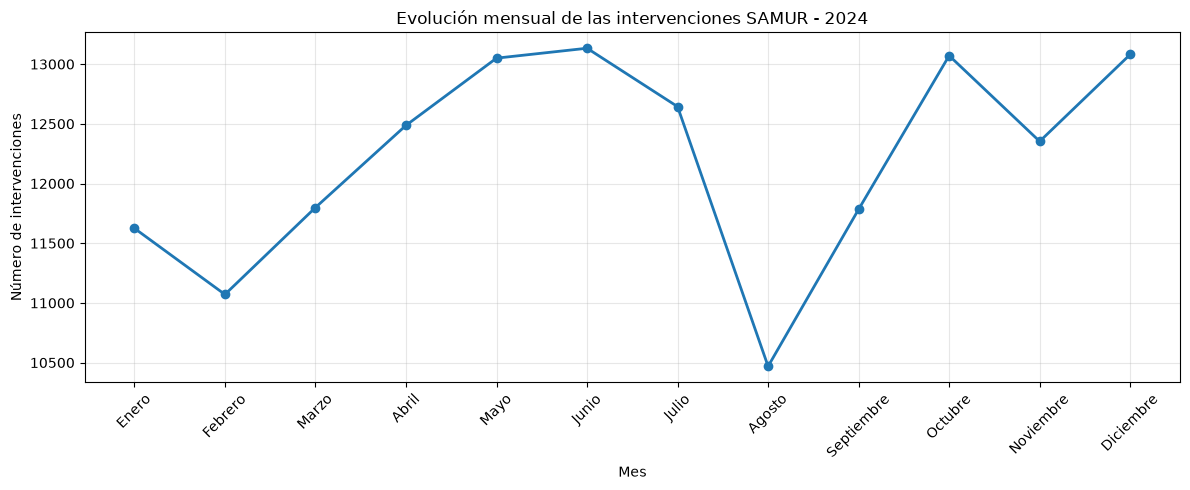

In [3]:
import matplotlib.pyplot as plt
import calendar
import pandas as pd
dataset_modelado = pd.read_csv(r"C:\Users\bario\OneDrive\Documentos\UC3M\PROYECTO EN CIENCIA DE DATOS\proyecto_emergencias-20260915T155207Z-1-001\proyecto_emergencias\datasets limpios\dataset_samur_modelado.csv")

# 1. Agrupar las intervenciones por mes
intervenciones_mes = (
    dataset_modelado
    .groupby('mes_num')['total_intervenciones']
    .sum()
    .reset_index()
    .sort_values('mes_num')
)

# 2. Añadir nombre del mes
meses_es = [
    'Enero', 'Febrero', 'Marzo', 'Abril',
    'Mayo', 'Junio', 'Julio', 'Agosto',
    'Septiembre', 'Octubre', 'Noviembre', 'Diciembre'
]

intervenciones_mes['mes_nombre'] = meses_es

# 3. Identificar máximos y mínimos
mes_max = intervenciones_mes.loc[
    intervenciones_mes['total_intervenciones'].idxmax()
]

mes_min = intervenciones_mes.loc[
    intervenciones_mes['total_intervenciones'].idxmin()
]

print("Mes con más intervenciones:",
      mes_max['mes_nombre'],
      int(mes_max['total_intervenciones']))

print("Mes con menos intervenciones:",
      mes_min['mes_nombre'],
      int(mes_min['total_intervenciones']))

# 4. Representar evolución mensual
plt.figure(figsize=(12, 5))

plt.plot(
    intervenciones_mes['mes_nombre'],
    intervenciones_mes['total_intervenciones'],
    marker='o',
    linewidth=2
)

plt.title('Evolución mensual de las intervenciones SAMUR - 2024')
plt.xlabel('Mes')
plt.ylabel('Número de intervenciones')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

,franja_horaria,total_intervenciones,porcentaje
0,1. Madrugada (00:00 - 05:59),20562,14.166523
1,2. Mañana (06:00 - 11:59),31007,21.362775
2,3. Tarde (12:00 - 17:59),50621,34.876158
3,4. Noche (18:00 - 23:59),42955,29.594543


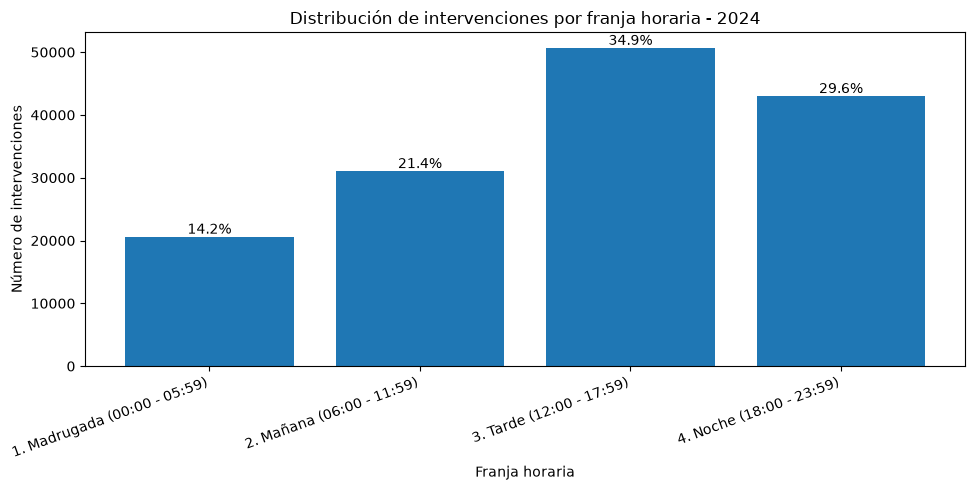

In [4]:
# 1. Agrupar intervenciones por franja horaria
intervenciones_franja = (
    dataset_modelado
    .groupby('franja_horaria')['total_intervenciones']
    .sum()
    .reset_index()
)

# 2. Excluir Desconocido SOLO de la visualización
# Conservamos todos los datos en el dataset original
orden_franjas = [
    '1. Madrugada (00:00 - 05:59)',
    '2. Mañana (06:00 - 11:59)',
    '3. Tarde (12:00 - 17:59)',
    '4. Noche (18:00 - 23:59)'
]

intervenciones_franja_real = (
    intervenciones_franja[
        intervenciones_franja['franja_horaria'].isin(orden_franjas)
    ]
    .copy()
)

intervenciones_franja_real['franja_horaria'] = pd.Categorical(
    intervenciones_franja_real['franja_horaria'],
    categories=orden_franjas,
    ordered=True
)

intervenciones_franja_real = (
    intervenciones_franja_real
    .sort_values('franja_horaria')
)

# 3. Calcular porcentajes sobre el total de las cuatro franjas conocidas
total_conocido = intervenciones_franja_real[
    'total_intervenciones'
].sum()

intervenciones_franja_real['porcentaje'] = (
    intervenciones_franja_real['total_intervenciones']
    / total_conocido * 100
)

display(intervenciones_franja_real)

# 4. Representar distribución
plt.figure(figsize=(10, 5))

barras = plt.bar(
    intervenciones_franja_real['franja_horaria'].astype(str),
    intervenciones_franja_real['total_intervenciones']
)

plt.title('Distribución de intervenciones por franja horaria - 2024')
plt.xlabel('Franja horaria')
plt.ylabel('Número de intervenciones')
plt.xticks(rotation=20, ha='right')

# Añadir porcentajes encima de las barras
for barra, porcentaje in zip(
    barras,
    intervenciones_franja_real['porcentaje']
):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height(),
        f'{porcentaje:.1f}%',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

TOP 5 DISTRITOS POR NÚMERO DE INTERVENCIONES


,distrito,total_intervenciones,poblacion,intervenciones_1000_hab
3,CENTRO,21182,149718.0,141.479314
2,CARABANCHEL,10421,257329.0,40.496796
12,PUENTE DE VALLECAS,9698,244458.0,39.671436
9,LATINA,8314,233765.0,35.565632
10,MONCLOA-ARAVACA,7995,123606.0,64.681326


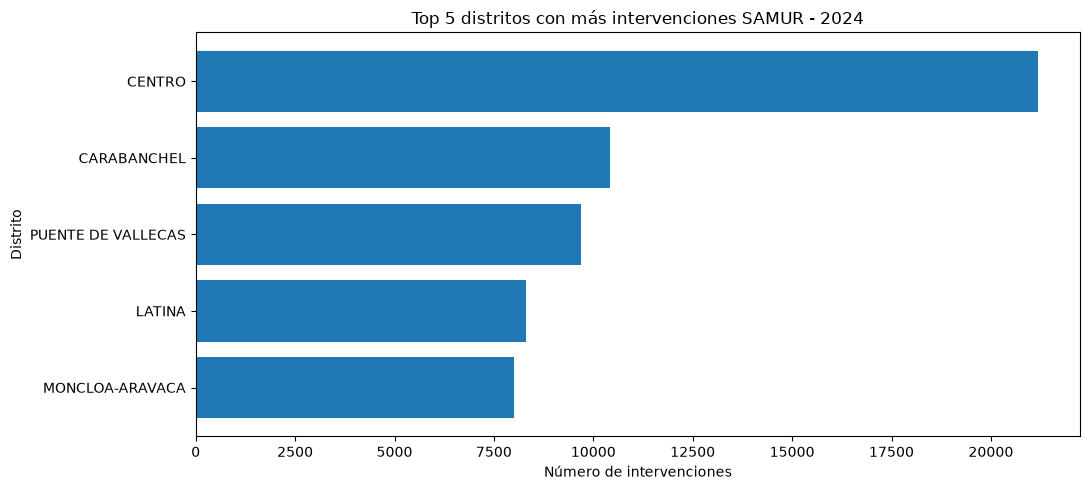

TOP 5 DISTRITOS POR CADA 1.000 HABITANTES


,distrito,total_intervenciones,poblacion,intervenciones_1000_hab
3,CENTRO,21182,149718.0,141.479314
10,MONCLOA-ARAVACA,7995,123606.0,64.681326
16,TETUAN,7957,155159.0,51.282878
14,SALAMANCA,7523,147707.0,50.931913
5,CHAMBERI,7001,137532.0,50.904517


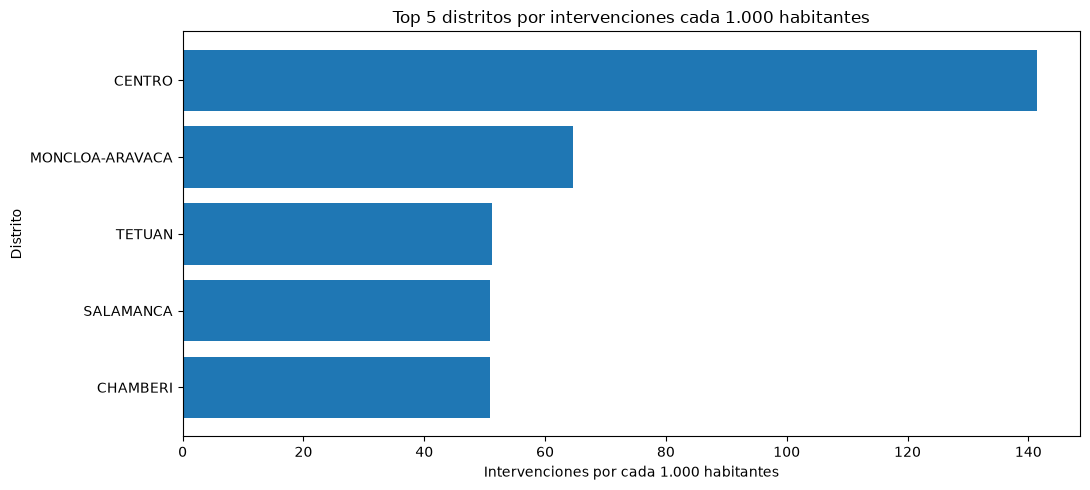

In [5]:
# 1. Agrupar intervenciones por distrito
intervenciones_distrito = (
    dataset_modelado[
        dataset_modelado['distrito'] != 'OTROS / DISTRITO NO IDENTIFICADO'
    ]
    .groupby('distrito')
    .agg(
        total_intervenciones=('total_intervenciones', 'sum'),
        poblacion=('poblacion', 'first')
    )
    .reset_index()
)

# 2. Calcular intervenciones por cada 1.000 habitantes
intervenciones_distrito['intervenciones_1000_hab'] = (
    intervenciones_distrito['total_intervenciones']
    / intervenciones_distrito['poblacion'] * 1000
)

# 3. Mostrar los cinco distritos con más intervenciones
top_distritos = intervenciones_distrito.sort_values(
    'total_intervenciones',
    ascending=False
).head(5)

print("TOP 5 DISTRITOS POR NÚMERO DE INTERVENCIONES")
display(top_distritos)

# 4. Gráfico de intervenciones absolutas
plt.figure(figsize=(11, 5))

plt.barh(
    top_distritos.sort_values('total_intervenciones')['distrito'],
    top_distritos.sort_values('total_intervenciones')['total_intervenciones']
)

plt.title('Top 5 distritos con más intervenciones SAMUR - 2024')
plt.xlabel('Número de intervenciones')
plt.ylabel('Distrito')
plt.tight_layout()
plt.show()

# 5. Top 5 por tasa de intervenciones por población
top_tasa = intervenciones_distrito.sort_values(
    'intervenciones_1000_hab',
    ascending=False
).head(5)

print("TOP 5 DISTRITOS POR CADA 1.000 HABITANTES")
display(top_tasa)

# 6. Gráfico de tasas
plt.figure(figsize=(11, 5))

plt.barh(
    top_tasa.sort_values('intervenciones_1000_hab')['distrito'],
    top_tasa.sort_values('intervenciones_1000_hab')['intervenciones_1000_hab']
)

plt.title('Top 5 distritos por intervenciones cada 1.000 habitantes')
plt.xlabel('Intervenciones por cada 1.000 habitantes')
plt.ylabel('Distrito')
plt.tight_layout()
plt.show()